# JEPX 翌日スポット価格予測｜最終テストの診断（日本語版）

**対象：LightGBM 回帰モデル A の評価**（チームで別途選択した Extra Trees 等の最終モデルとは別実験）。

このNotebookは、**学習済みの予測結果を使った事後評価**です。テスト結果に合わせた再学習やハイパーパラメータの探索は実行しません。

- 同梱の期間別・月別CSVから、サマリーの整合性を検証します。
- 手元にテスト予測明細CSVがある場合だけ、オプションのセルで行ごとに MAE を再計算できます。
- **検証期間2,928件の元データと学習済みモデルは同梱されていません。** その期間の値は提供された集計表を引用しています。

In [1]:
from pathlib import Path
import csv
import math
from collections import defaultdict

# 実行ディレクトリが notebooks/ でもリポジトリ直下でも動作するように、
# 同梱の results/ フォルダを見つけます。
HERE = Path.cwd()
ROOT = next((p for p in [HERE, *HERE.parents]
             if (p / 'results' / 'FINAL_period_MAE_comparison.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('lightgbm_regression_evaluation フォルダ（または notebooks/）から実行してください。')

def read_csv(path):
    with path.open('r', encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))

period = read_csv(ROOT / 'results' / 'FINAL_period_MAE_comparison.csv')
monthly = read_csv(ROOT / 'results' / 'FINAL_monthly_MAE_diagnostics.csv')
print('集計データの読み込み先：', ROOT)
print('評価期間：', len(period), '件 / 月別：', len(monthly), 'か月')

集計データの読み込み先： /mnt/data/JEPX_日本語ポートフォリオ完成版/03_lightgbm_regression_evaluation
評価期間： 4 件 / 月別： 12 か月


In [2]:
# 月別集計を件数で重み付けすると、テスト全体のMAEと一致することを検証。
test = next(r for r in period if r['period'] == 'test_all')
assert len(monthly) == 12
n = sum(int(r['n_rows']) for r in monthly)
assert n == int(test['n_rows']) == 17520
for column in ('baseline_mae', 'model_A_mae'):
    weighted = sum(int(r['n_rows'])*float(r[column]) for r in monthly)/n
    expected = float(test[column])
    assert math.isclose(weighted, expected, abs_tol=1e-10), (column, weighted, expected)
    print(f'{column}: 月別加重平均 {weighted:.6f} / テスト集計 {expected:.6f}')

baseline = float(test['baseline_mae'])
model = float(test['model_A_mae'])
print(f'テスト全体（{n:,}件）：ベースライン {baseline:.6f}、LightGBM A {model:.6f}')
print(f'モデルAの相対的な悪化：{(model/baseline-1)*100:.2f}%')
print('注意：これは同梱済みの集計表同士の算術チェックであり、原本の再計算とは異なります。')

baseline_mae: 月別加重平均 3.273166 / テスト集計 3.273166
model_A_mae: 月別加重平均 4.217821 / テスト集計 4.217821
テスト全体（17,520件）：ベースライン 3.273166、LightGBM A 4.217821
モデルAの相対的な悪化：28.86%
注意：これは同梱済みの集計表同士の算術チェックであり、原本の再計算とは異なります。


## 期間別・月別の結果

以下のグラフは、提出用PNGとして `../figures/` に保存されています。Notebook上でも表示します。

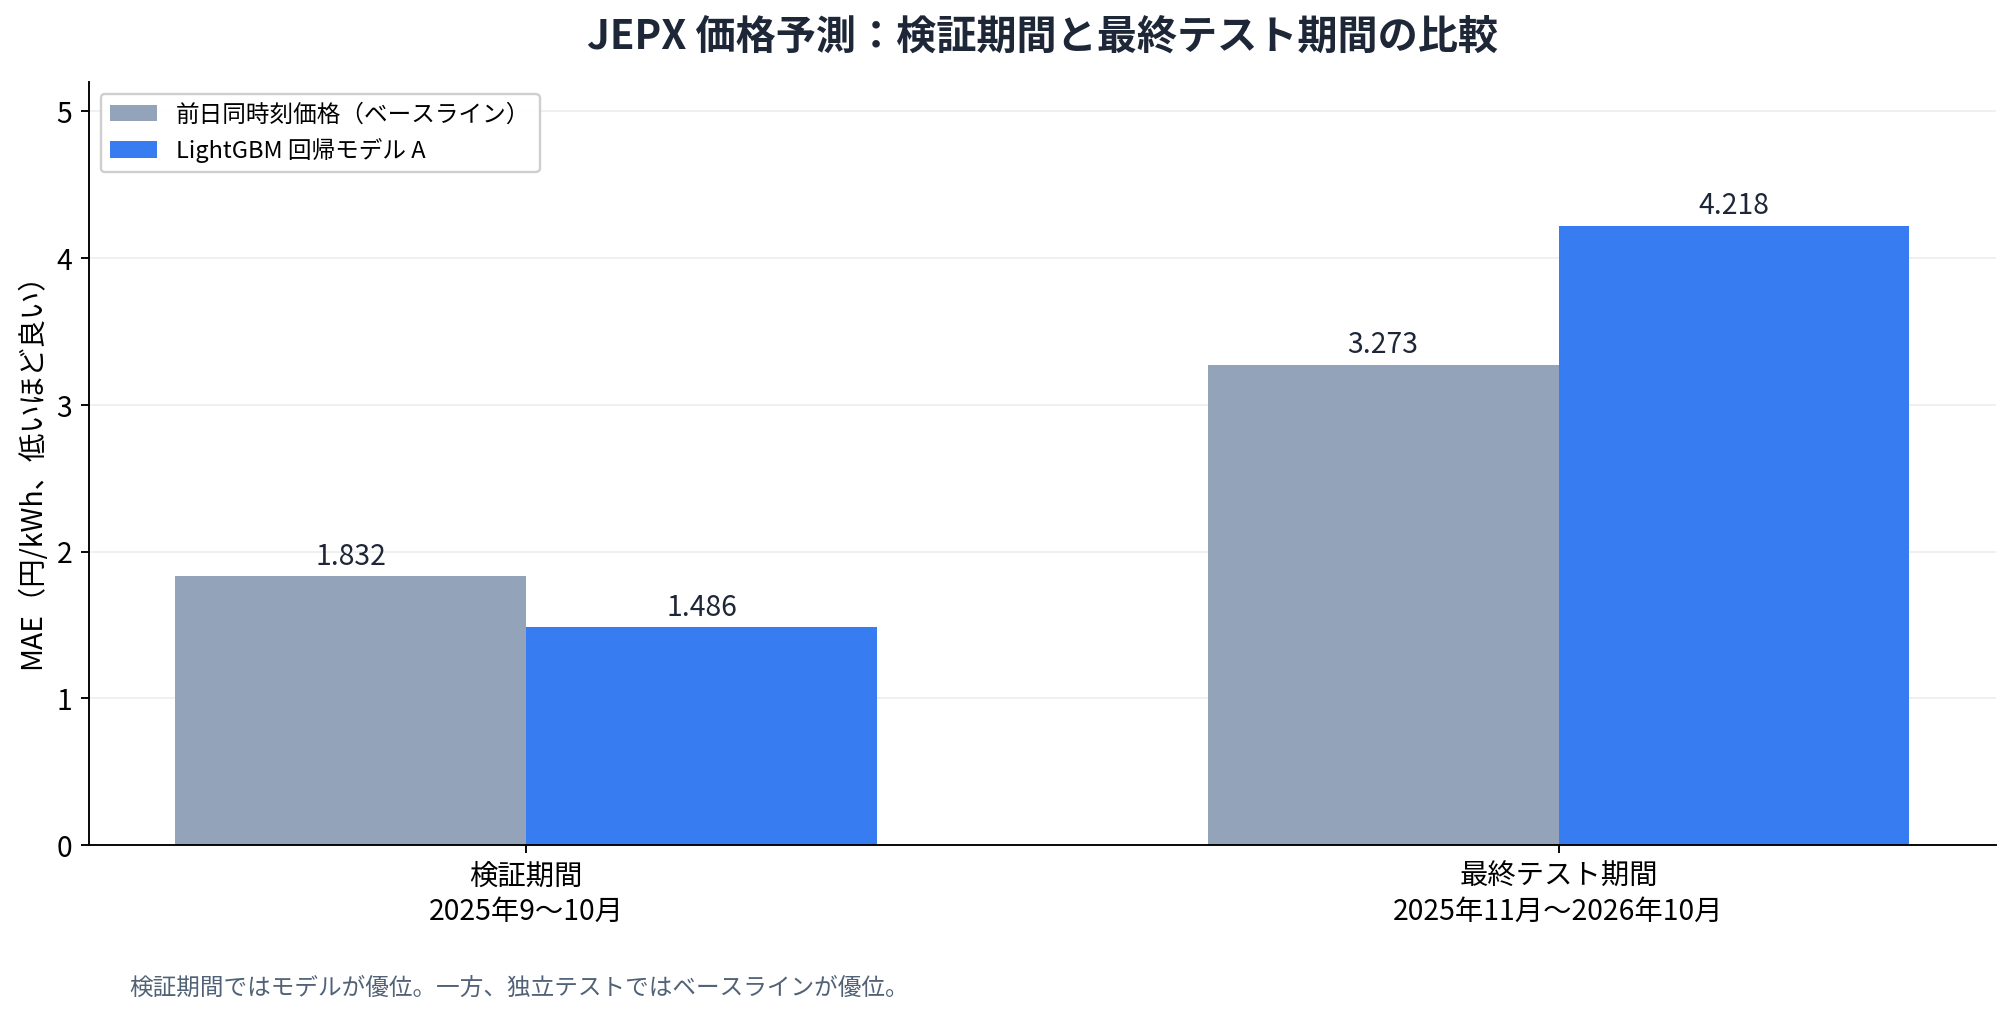

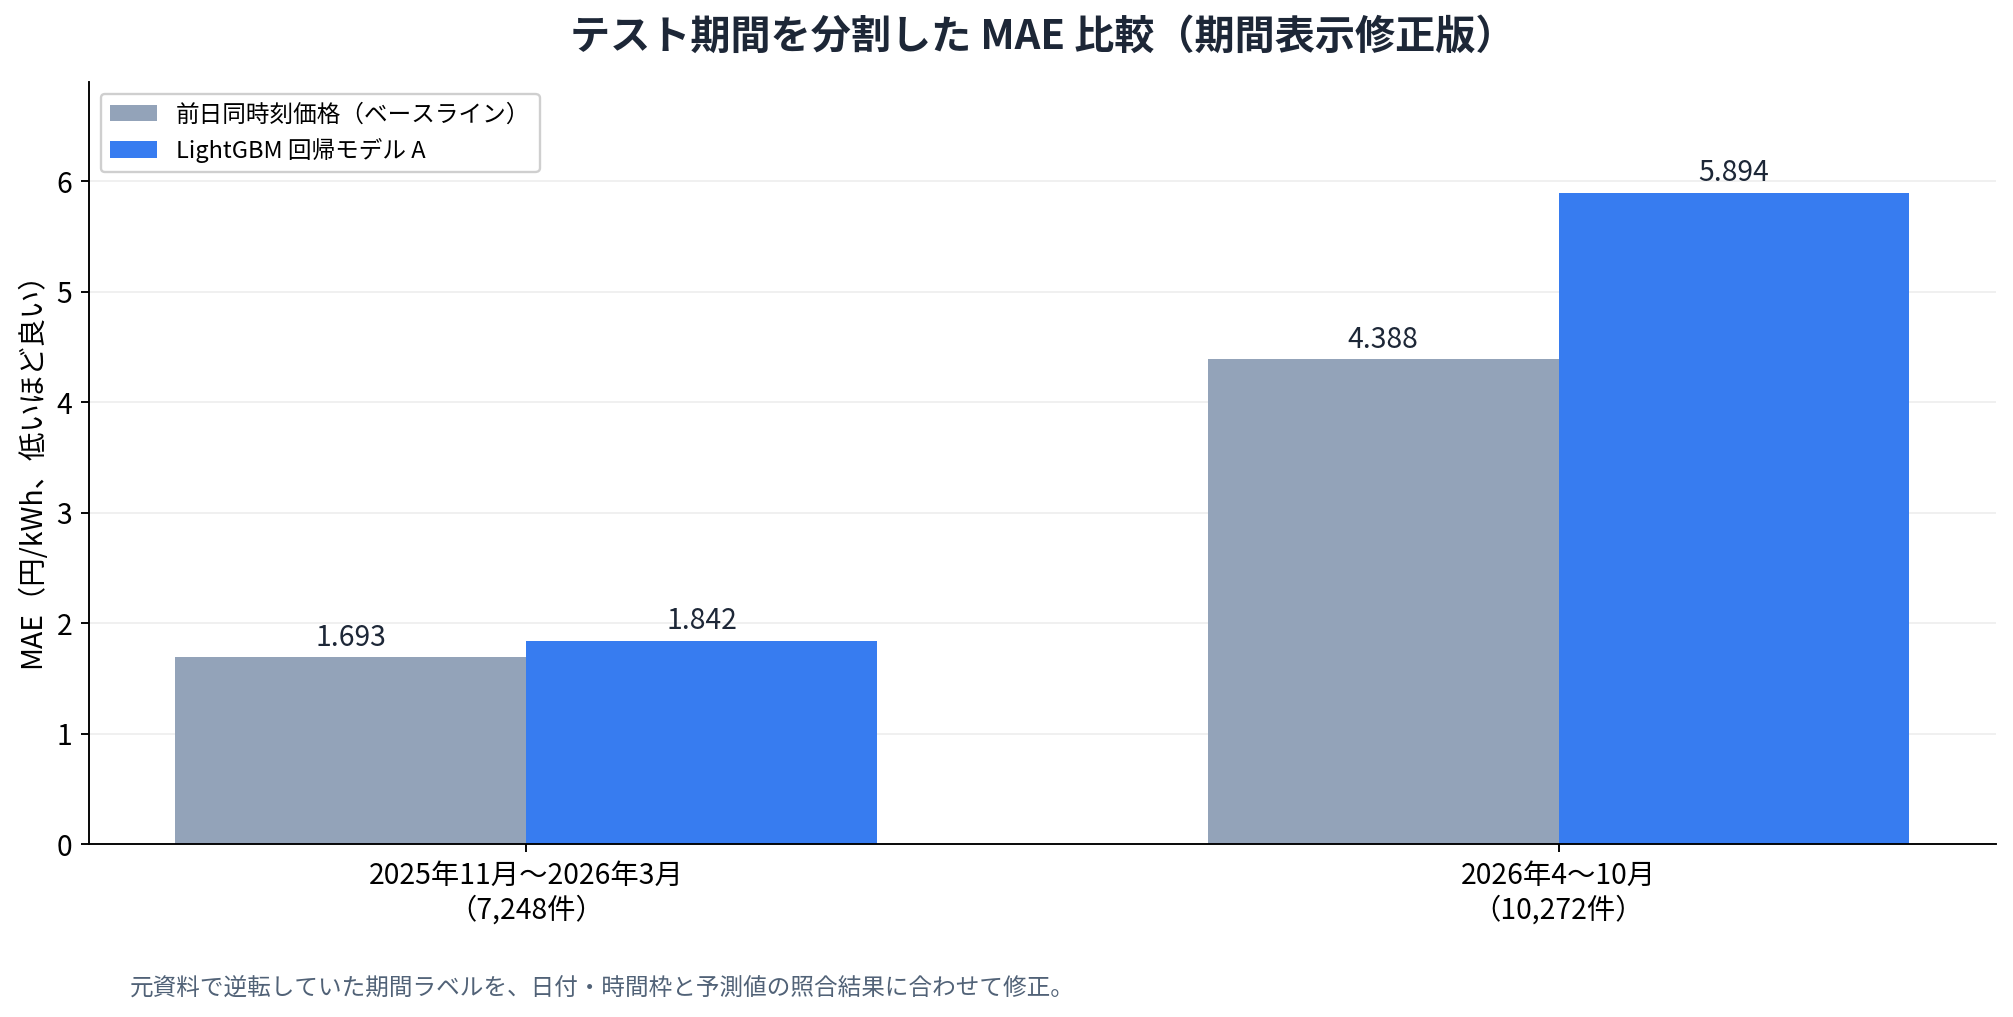

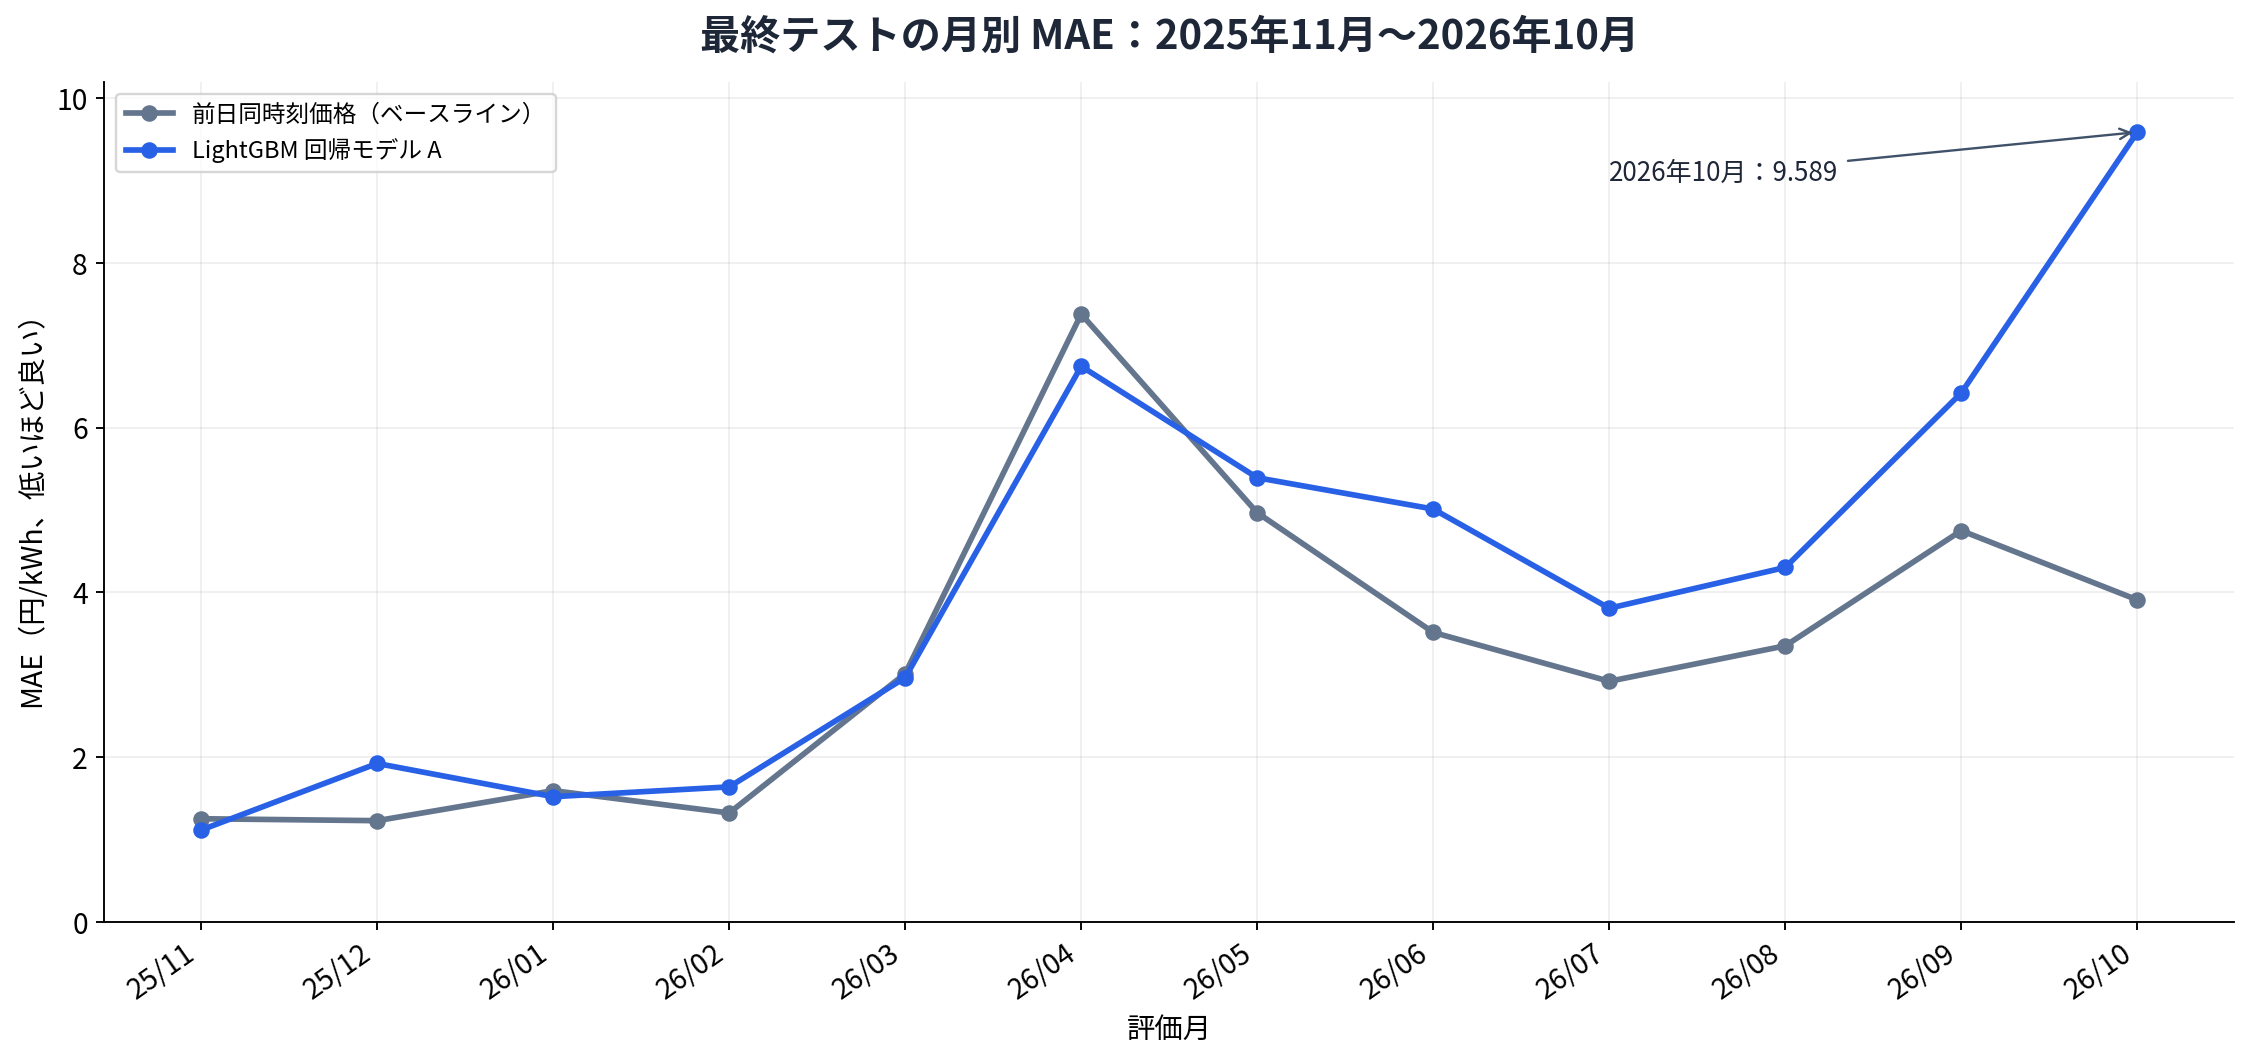

In [3]:
from IPython.display import display, Image
for filename in ('01_validation_vs_test_MAE_JA.png',
                 '02_test_subperiod_MAE_corrected_JA.png',
                 '03_monthly_test_MAE_JA.png'):
    path = ROOT / 'figures' / filename
    if path.exists():
        display(Image(filename=str(path), width=790))
    else:
        print('画像が見つかりません：', path)

## オプション：手元の予測明細CSVから独立に再計算

以下は**元の予測明細を所有し、利用許可がある場合のみ**実行する診断です。次のいずれかに、必要な列 `date, slot, y_price, baseline_pred, y_price_pred` を含むCSVを置きます。

- `data/BI_2_테스트예측.csv`（元の韓国語ファイル名）
- `data/BI_2_テスト予測.csv`

`data/` はこの成果物の直下に自分で作成してください。**原票・予測明細を公開GitHubにPushしないでください。**（`.gitignore` が同梱されています）

この集計を使って、同じ期間区分で 17,520 件の MAE を再計算します。

In [4]:
private_candidates = [
    ROOT / 'data' / 'BI_2_테스트예측.csv',
    ROOT / 'data' / 'BI_2_テスト予測.csv',
]
private_csv = next((p for p in private_candidates if p.exists()), None)
if private_csv is None:
    print('予測明細CSVは未配置です。個票からの再計算はスキップしました。')
else:
    records = read_csv(private_csv)
    keys = set()
    periods = defaultdict(list)
    for row in records:
        key = (row['date'], int(row['slot']))
        assert key not in keys, f'重複キー：{key}'
        keys.add(key)
        y = float(row['y_price'])
        b = float(row['baseline_pred'])
        a = float(row['y_price_pred'])
        assert all(math.isfinite(v) for v in (y,b,a))
        periods['test_all'].append((abs(y-b), abs(y-a)))
        group = 'test_2025_11_to_2026_03' if row['date'] < '2026-04-01' else 'test_2026_04_to_2026_10'
        periods[group].append((abs(y-b), abs(y-a)))
    assert len(keys) == 17520, f'行数不一致：{len(keys)}'
    for row in period:
        label = row['period']
        if label == 'validation_2025_09_to_2025_10':
            continue  # 検証期間の生データは同梱していないため比較しない
        items = periods[label]
        assert len(items) == int(row['n_rows'])
        b_mae = sum(x[0] for x in items)/len(items)
        a_mae = sum(x[1] for x in items)/len(items)
        assert math.isclose(b_mae,float(row['baseline_mae']),abs_tol=1e-9)
        assert math.isclose(a_mae,float(row['model_A_mae']),abs_tol=1e-9)
        print(f'{label}: {len(items):,}件 / 基準 {b_mae:.6f} / モデルA {a_mae:.6f}  ✓')
    print('明細CSVからの再計算が、添付された期間別集計と一致しました。')

予測明細CSVは未配置です。個票からの再計算はスキップしました。


## 解釈上の注意

- **確定した観測結果**：テスト全体でモデルAのMAEはベースラインより 28.86% 高くなりました。2026年10月の月別MAEは 9.589211 でした。
- **考えられる仮説**：学習時期とテスト時期で価格分布が異なる可能性があります。ただし原因は未確定です。
- **検証できていない点**：学習用特徴量を生成した当時の公表時点データや、事後訂正の有無を完全に再構成できていません。
- **避けるべき操作**：テスト期間の結果を見てモデルや特徴量を再選択すると、テスト期間の独立性を損ないます。

追加の前提と根拠は [TECHNICAL_REPORT_JA.md](../TECHNICAL_REPORT_JA.md) を参照してください。